# Imports

In [173]:
import torch 
import torch.nn as nn
import math
from typing import List, Union
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from torch.utils.data import Dataset 

from torch.utils.data import DataLoader
import random
import seaborn as sns
import pickle
from torch.nn.utils.rnn import pad_sequence
import pandas as pd
from PIL import Image
import glob
import os
from csv_runs import notebook_csv_path


In [174]:
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

# Dataset

In [175]:
df = pd.read_parquet(r'legacy/datasets/bert_trainset_squared_25_with_vis.gzip')
print(df.shape)
df.head(2)

(24000, 11)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.964, 0.586]",0.002947,"[0.01924901314411513, -0.003948870736979841]",-5.345884,"[0.9795991420207817, -0.20096149121696957]",TSEHVLKJGFLVAAAAAAAA,2174,0.820687,NaN,1
1,0.30,"[0.971, 0.588]",0.009698,"[0.04181333823597422, 0.016644679076252743]",3.874422,"[0.929093399643261, 0.3698451767149704]",KDZDVQEXAAAAAAAAAAAA,1288,0.486221,2174.0,1


In [177]:
df['change_of_position_state'].mean()

0.8854583333333333

### tokenized dataset

In [178]:
# with open('ps_to_psid.pkl', 'rb') as file:
#     ps_to_psid = pickle.load(file)

In [179]:
# df['position_state_id'] = [ps_to_psid[k] for k in df['position_state']]

#### vocab size

In [180]:
df['position_state_id'].nunique()

2649

#### token freqs

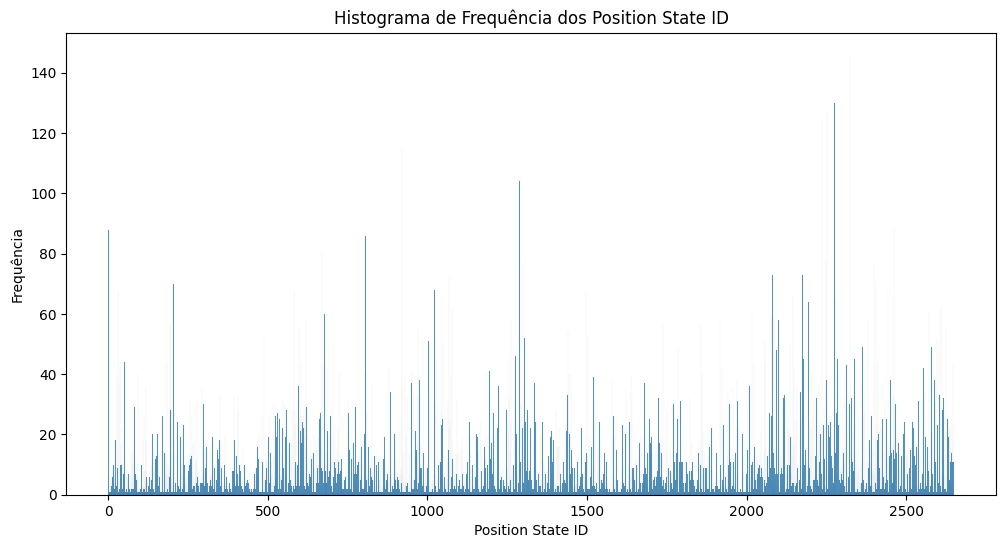

In [181]:
fig, ax = plt.subplots(figsize=(12, 6))
plt.title('Histograma de Frequência dos Position State ID')
sns.histplot(df['position_state_id'],binwidth=1,)
plt.ylabel('Frequência')
plt.xlabel('Position State ID')
plt.show()

# Classes

In [86]:
def collate_masked_batch(batch, pad_token_id=0):
    xs, ys = zip(*batch)
    x = pad_sequence(xs, batch_first=True, padding_value=pad_token_id)
    y = pad_sequence(ys, batch_first=True, padding_value=-100)
    # attention_mask: 1 onde não é PAD
    attention_mask = (x != pad_token_id).long()
    return x, y, attention_mask

### dataset class

In [87]:
class TrajectoryARDataset(Dataset):
    def __init__(
        self,
        full_sequence,
        min_len=4,
        max_len=32,
        bos_token_id=None,
        eos_token_id=None,
    ):
        """
        Autoregressivo: para cada janela, x = tokens[0..T-2], y = tokens[1..T-1].
        """
        assert min_len >= 2, "min_len precisa ser ≥ 2 para AR"
        self.full_sequence = list(full_sequence)
        if bos_token_id is not None:
            self.full_sequence = [bos_token_id] + self.full_sequence
        if eos_token_id is not None:
            self.full_sequence = self.full_sequence + [eos_token_id]

        self.min_len = min_len
        self.max_len = max_len

        # garante que ainda há pelo menos min_len tokens a partir de start
        self.start_indices = list(range(0, max(1, len(self.full_sequence) - self.min_len)))

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        start = self.start_indices[idx]
        seq_len = random.randint(self.min_len, self.max_len)
        end = min(start + seq_len, len(self.full_sequence))
        seq = self.full_sequence[start:end]

        # força pelo menos 2 tokens (raríssimo não cumprir devido à construção de start_indices)
        if len(seq) < 2:
            end = min(start + 2, len(self.full_sequence))
            seq = self.full_sequence[start:end]

        x = torch.tensor(seq[:-1], dtype=torch.long)  # input
        y = torch.tensor(seq[1:],  dtype=torch.long)  # alvo (próximo token)
        return x, y


### model class

In [182]:
class TrajectoryBERT(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_size,
        num_layers,
        num_heads,
        hidden_dim,
        dropout=0.1,
        max_len=512,
        pad_token_id=0,
        causal=False,   # <--- NOVO: ativa máscara causal (GPT-like)
    ):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.max_len = max_len
        self.causal = causal

        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=pad_token_id)
        self.position_embedding = nn.Embedding(max_len, embed_size)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    @staticmethod
    def _causal_mask(T, device):
        """
        Máscara booleana (True = NÃO pode atender), shape [T, T].
        Triângulo superior (posições futuras) é True.
        """
        return torch.triu(torch.ones(T, T, device=device, dtype=torch.bool), diagonal=1)

    def forward(self, x, attention_mask: torch.Tensor = None):
        """
        x: [B, T] (com PAD)
        attention_mask: [B, T], 1=válido, 0=PAD (igual ao seu collate)
        """
        B, T = x.size()
        device = x.device

        if T > self.max_len:
            x = x[:, : self.max_len]
            T = self.max_len

        pos = torch.arange(T, device=device).unsqueeze(0).expand(B, T)
        h = self.embedding(x) + self.position_embedding(pos)

        # padding mask (True=ignorar)
        if attention_mask is None:
            key_padding_mask = (x == self.pad_token_id)
        else:
            key_padding_mask = (attention_mask == 0) if attention_mask.dtype != torch.bool else attention_mask

        # máscara causal opcional
        src_mask = self._causal_mask(T, device) if self.causal else None

        h = self.encoder(h, mask=src_mask, src_key_padding_mask=key_padding_mask)
        logits = self.fc_out(h)  # [B, T, V]
        return logits

    @torch.no_grad()
    def generate(self, prompt_ids, max_new_tokens=50, eos_token_id=None, temperature=1.0, top_k=None):
        """
        Geração autoregressiva simples (amostragem).
        prompt_ids: 1D LongTensor [T0]
        """
        assert self.causal, "Ative causal=True para gerar de forma autoregressiva."
        self.eval()
        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)  # [1, T]

        for _ in range(max_new_tokens):
            logits = self.forward(x)[:, -1, :]  # último passo
            logits = logits / max(temperature, 1e-8)

            if top_k is not None and top_k > 0:
                vals, idxs = torch.topk(logits, k=top_k, dim=-1)
                filt = torch.full_like(logits, float("-inf"))
                logits = filt.scatter(1, idxs, vals)

            probs = torch.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)  # [1,1]
            x = torch.cat([x, next_id], dim=1)

            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        return x.squeeze(0)  # [T_total]
    
    @torch.no_grad()
    def generate_with_distributions(
        self,
        prompt_ids: torch.Tensor,
        max_new_tokens: int = 50,
        eos_token_id: int = None,
        temperature: float = 1.0,
        top_k: int = None,
        return_logits: bool = False,        # logits após temperatura+top_k (os que geram as probs)
        return_raw_logits: bool = False,    # logits “crus” (antes de temperatura e top_k)
        to_cpu: bool = True,                # armazena em CPU para poupar VRAM
    ):
        """
        Gera tokens de forma autoregressiva e coleta a distribuição por passo.

        Retorno:
          tokens: LongTensor [T_total]
          dists: dict com tensores empilhados ao longo do tempo:
                 - 'probs':  [num_passos, vocab_size] (sempre presente)
                 - 'logits': [num_passos, vocab_size] se return_logits=True
                 - 'logits_raw': [num_passos, vocab_size] se return_raw_logits=True

        Observação: 'probs' e 'logits' refletem exatamente a distribuição usada
        para amostragem (após aplicar temperatura e top_k).
        """
        assert self.causal, "Ative causal=True para geração autoregressiva."
        self.eval()

        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)  # [1, T0]

        probs_list = []
        logits_list = [] if return_logits else None
        logits_raw_list = [] if return_raw_logits else None

        for _ in range(max_new_tokens):
            # 1) logits antes de qualquer ajuste
            logits_raw = self.forward(x)[:, -1, :].squeeze(0)  # [vocab_size]

            # 2) aplica temperatura
            logits_adj = logits_raw / max(temperature, 1e-8)

            # 3) top-k (opcional)
            if top_k is not None and top_k > 0:
                k = min(top_k, logits_adj.shape[-1])
                vals, idxs = torch.topk(logits_adj, k=k, dim=-1)
                tmp = torch.full_like(logits_adj, float('-inf'))
                logits_adj = tmp.scatter(0, idxs, vals)

            # 4) softmax -> distribuição usada para amostrar
            probs = torch.softmax(logits_adj, dim=-1)  # [vocab_size]

            # 5) armazena as distribuições
            target_device = torch.device('cpu') if to_cpu else device
            probs_list.append(probs.detach().to(target_device))
            if return_logits:
                logits_list.append(logits_adj.detach().to(target_device))
            if return_raw_logits:
                logits_raw_list.append(logits_raw.detach().to(target_device))

            # 6) amostra próximo token
            next_id = torch.multinomial(probs.unsqueeze(0), num_samples=1)  # [1,1]
            x = torch.cat([x, next_id], dim=1)

            # 7) parada opcional por EOS
            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        # monta saída
        out_tokens = x.squeeze(0)  # [T_total]
        dists = {
            'probs': torch.stack(probs_list, dim=0)  # [num_passos, vocab_size]
        }
        if return_logits:
            dists['logits'] = torch.stack(logits_list, dim=0)
        if return_raw_logits:
            dists['logits_raw'] = torch.stack(logits_raw_list, dim=0)

        return out_tokens, dists


# Definitions

In [214]:
# Hiperparâmetros
embed_size = 16
num_layers = 1
num_heads = 2
hidden_dim = 32
mask_token_id = df['position_state_id'].max()
pad_token_id = df['position_state_id'].max() + 1
vocab_size = pad_token_id + 1
max_len = 10
dropout = 0.2
batch_size = 128
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_epochs = 5e2
# Simulando dados
sequences = df[df['change_of_position_state'] == 1]['position_state_id'].values

device, vocab_size

(device(type='cuda'), 2651)

In [215]:
max_len

10

In [216]:
sequences

array([2174, 1288, 2178, ..., 2438, 2468, 1294])

In [217]:
mask_token_id, pad_token_id

(2649, 2650)

# Model

### init datasets

In [218]:
# help(torch.utils.data.random_split)

In [219]:
# [Célula] Dataset e dataloaders
dataset = TrajectoryARDataset(
    full_sequence=sequences,   # sua sequência única (lista de ids)
    min_len=3,                 # por ex.
    max_len=max_len,           # seu valor existente
    bos_token_id=None,
    eos_token_id=None,
)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size], )

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
)
val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False,
    collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
)

### init model

In [220]:
# [Célula] Inicialização do modelo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TrajectoryBERT(
    vocab_size,
    embed_size=embed_size,
    num_layers=num_layers,
    num_heads=num_heads,
    hidden_dim=hidden_dim,
    dropout=dropout,
    pad_token_id=pad_token_id,
    max_len=max_len,   # ajuste se necessário
    causal= True
).to(device)

### init optim and loss

In [221]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Params: {trainable_params}")

Total Trainable Params: 89867


In [222]:
# [Célula] Otimizador e critério
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
# per-token para conseguirmos média apenas nos alvos válidos (-100 é ignorado)
criterion = nn.CrossEntropyLoss(ignore_index=-100, reduction='none')

# Train

## train loop

In [223]:
# [Célula] Loop de treinamento
train_losses, val_losses = [], []
train_perplexities, val_perplexities = [], []

for epoch in range(int(num_epochs)):
    model.train()
    train_nll_sum = 0.0
    train_tok_count = 0

    for x, y, attn in train_loader:
        x, y, attn = x.to(device), y.to(device), attn.to(device)

        optimizer.zero_grad()
        # pode passar a máscara (agora suportada), mas não é obrigatório
        logits = model(x, attention_mask=attn)

        # perda por token e média apenas onde y != -100
        loss_vec = criterion(logits.view(-1, vocab_size), y.view(-1))  # [B*T]
        valid = (y.view(-1) != -100)
        loss = loss_vec[valid].mean()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # opcional, ajuda na estabilidade
        optimizer.step()

        train_nll_sum += loss_vec[valid].sum().item()
        train_tok_count += valid.sum().item()

    # ---- validação ----
    model.eval()
    val_nll_sum = 0.0
    val_tok_count = 0
    with torch.no_grad():
        for x_val, y_val, attn_val in val_loader:
            x_val, y_val, attn_val = x_val.to(device), y_val.to(device), attn_val.to(device)
            val_logits = model(x_val, attention_mask=attn_val)

            v_loss_vec = criterion(val_logits.view(-1, vocab_size), y_val.view(-1))
            v_valid = (y_val.view(-1) != -100)
            val_nll_sum += v_loss_vec[v_valid].sum().item()
            val_tok_count += v_valid.sum().item()

    # perdas médias por token e perplexidade
    avg_train_loss = train_nll_sum / max(1, train_tok_count)
    avg_val_loss   = val_nll_sum   / max(1, val_tok_count)
    train_ppl = math.exp(avg_train_loss)
    val_ppl   = math.exp(avg_val_loss)

    train_losses.append(avg_train_loss);  val_losses.append(avg_val_loss)
    train_perplexities.append(train_ppl); val_perplexities.append(val_ppl)

    if (epoch + 1) % max(1, num_epochs // 10) == 0 or (epoch + 1) == num_epochs or epoch==1:
        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
            f"Train PPL: {train_ppl:.2f} | Val PPL: {val_ppl:.2f}"
        )


Epoch 2/500.0 | Train Loss: 8.0027 | Val Loss: 7.9840 | Train PPL: 2989.00 | Val PPL: 2933.74
Epoch 50/500.0 | Train Loss: 6.9554 | Val Loss: 6.9889 | Train PPL: 1048.76 | Val PPL: 1084.48
Epoch 100/500.0 | Train Loss: 5.8042 | Val Loss: 5.8153 | Train PPL: 331.70 | Val PPL: 335.39
Epoch 150/500.0 | Train Loss: 4.8128 | Val Loss: 4.8557 | Train PPL: 123.08 | Val PPL: 128.47
Epoch 200/500.0 | Train Loss: 4.1128 | Val Loss: 4.1842 | Train PPL: 61.12 | Val PPL: 65.64
Epoch 250/500.0 | Train Loss: 3.6467 | Val Loss: 3.7493 | Train PPL: 38.35 | Val PPL: 42.49
Epoch 300/500.0 | Train Loss: 3.3267 | Val Loss: 3.4444 | Train PPL: 27.85 | Val PPL: 31.32
Epoch 350/500.0 | Train Loss: 3.1004 | Val Loss: 3.2427 | Train PPL: 22.21 | Val PPL: 25.60
Epoch 400/500.0 | Train Loss: 2.9310 | Val Loss: 3.0784 | Train PPL: 18.75 | Val PPL: 21.72
Epoch 450/500.0 | Train Loss: 2.7973 | Val Loss: 2.9701 | Train PPL: 16.40 | Val PPL: 19.49
Epoch 500/500.0 | Train Loss: 2.6950 | Val Loss: 2.8547 | Train PPL: 14

In [99]:
epoch

999

In [165]:
def add_shape_hooks(model):
    handles = []

    def fmt(x):
        if x is None:
            return "None"
        if torch.is_tensor(x):
            return str(tuple(x.shape))
        if isinstance(x, (list, tuple)):
            return "[" + ", ".join(fmt(i) for i in x) + "]"
        return str(type(x))

    def hook_fn(name):
        def hook(module, inputs, output):
            x = inputs[0] if isinstance(inputs, tuple) and len(inputs) > 0 else inputs
            print(f"{name}")
            print(f"  in : {fmt(x)}")
            print(f"  out: {fmt(output)}")
            print("-" * 40)
        return hook

    # principais blocos
    handles.append(model.embedding.register_forward_hook(hook_fn("Embedding")))
    handles.append(model.position_embedding.register_forward_hook(hook_fn("Positional Embedding")))

    for i, layer in enumerate(model.encoder.layers):
        handles.append(layer.self_attn.register_forward_hook(hook_fn(f"Layer {i} - SelfAttn (out, weights)")))
        handles.append(layer.linear1.register_forward_hook(hook_fn(f"Layer {i} - FFN Linear1")))
        handles.append(layer.linear2.register_forward_hook(hook_fn(f"Layer {i} - FFN Linear2")))

    handles.append(model.fc_out.register_forward_hook(hook_fn("fc_out")))

    return handles

def remove_hooks(handles):
    for h in handles:
        h.remove()

In [166]:
model.eval()
handles = add_shape_hooks(model)

with torch.no_grad():
    logits = model(x_val, attn_val)  # x_val: [B,T], attn_val: [B,T]

remove_hooks(handles)

Embedding
  Input shape : (67, 9)
  Output shape: (67, 9, 16)
----------------------------------------
Embedding
  Input shape : (67, 9)
  Output shape: (67, 9, 16)
----------------------------------------
Embedding
  in : (67, 9)
  out: (67, 9, 16)
----------------------------------------
Positional Embedding
  Input shape : (67, 9)
  Output shape: (67, 9, 16)
----------------------------------------
Positional Embedding
  Input shape : (67, 9)
  Output shape: (67, 9, 16)
----------------------------------------
Positional Embedding
  in : (67, 9)
  out: (67, 9, 16)
----------------------------------------
Final Linear (fc_out)
  Input shape : (67, 9, 16)
  Output shape: (67, 9, 948)
----------------------------------------
Final Linear (fc_out)
  Input shape : (67, 9, 16)
  Output shape: (67, 9, 948)
----------------------------------------
fc_out
  in : (67, 9, 16)
  out: (67, 9, 948)
----------------------------------------


## results plot

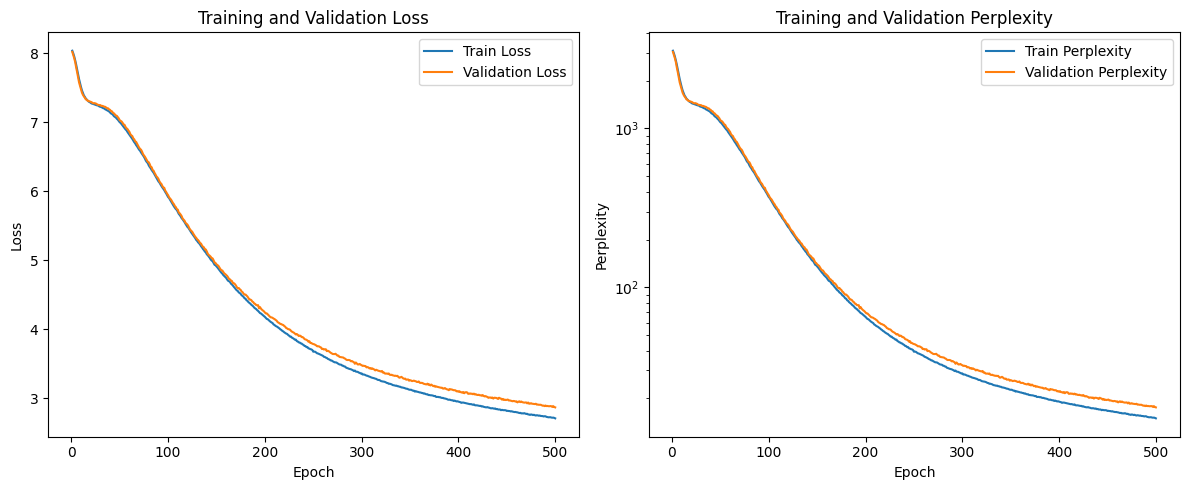

In [204]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]

# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(num_epochs) + 1), train_losses, label='Train Loss')
plt.plot(range(1, int(num_epochs) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(num_epochs) + 1), train_perplexities, label='Train Perplexity')
plt.plot(range(1, int(num_epochs) + 1), val_perplexities, label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
plt.yscale('log')
# plt.grid(True)
plt.tight_layout()
plt.show()


### save model

In [101]:
save_model = True

In [102]:
if save_model:
    torch.save(model.state_dict(), 'legacy/checkpoints/with_vis/gpt_model_with_vis.pt')

# Vizz Predictions

In [103]:
def show_next_token_prediction(
    model,
    dataloader,
    id_to_token=None,
    device=None,
    top_k=10,           # mostra top-k candidatos do último passo
):
    """
    Mostra a predição do *próximo token* no cenário autoregressivo.
    Considera apenas os logits da última posição válida do prompt.
    """
    if id_to_token is None:
        id_to_token = {}
    if device is None:
        device = next(model.parameters()).device

    # pega um batch e seleciona o primeiro exemplo
    x_batch, y_batch, attn_batch = next(iter(dataloader))
    x = x_batch[0]         # [T]
    y = y_batch[0]         # [T]
    attn = attn_batch[0]   # [T]

    # último índice válido (ignora PAD à direita)
    T_valid = int(attn.sum().item())
    if T_valid < 1:
        print("Exemplo sem tokens válidos.")
        return

    model.eval()
    with torch.no_grad():
        logits = model(x.unsqueeze(0).to(device),
                       attention_mask=attn.unsqueeze(0).to(device))  # [1, T, V]
        last_logits = logits[0, T_valid - 1, :].cpu()                 # [V]
        probs = torch.softmax(last_logits, dim=-1)
        pred_id = int(torch.argmax(probs).item())

    # alvo "gold" para o próximo token (deve existir em y[T_valid-1])
    gold_id = int(y[T_valid - 1].item())
    has_gold = (gold_id != -100)

    # helpers
    def tok2str(tid): return id_to_token.get(int(tid), str(int(tid)))

    prompt_ids = x[:T_valid].tolist()
    prompt_str = [tok2str(t) for t in prompt_ids]
    pred_str = tok2str(pred_id)
    gold_str = tok2str(gold_id) if has_gold else "-"

    # impressão principal
    print("\n=== Próximo token (AR) ===")
    print("Input (x):")
    print("[" + " ".join(prompt_str) + "]\n")
    print("Alvo (próximo token):", gold_str)
    print("Predição (argmax token):", pred_str)
    if has_gold:
        correto = ("SIM" if pred_id == gold_id else "NÃO")
        print("Correto?:", correto)
        print(f"p(gold) = {probs[gold_id].item():.4f} | p(pred) = {probs[pred_id].item():.4f}")

    # top-k candidatos do último passo
    if top_k is not None and top_k > 0:
        k = min(top_k, last_logits.numel())
        vals, idxs = torch.topk(probs, k=k)
        print("\nTop-{} candidatos:".format(k))
        for rank in range(k):
            tid = int(idxs[rank].item())
            print(f"{rank+1:>2}. {tok2str(tid):<12} p={vals[rank].item():.4f}")


In [25]:
show_next_token_prediction(
    model, val_loader,
    top_k=3
)


=== Próximo token (AR) ===
Input (x):
[115 120 76 114 76 114 25 115]

Alvo (próximo token): 81
Predição (argmax token): 114
Correto?: NÃO
p(gold) = 0.0229 | p(pred) = 0.1413

Top-3 candidatos:
 1. 114          p=0.1413
 2. 25           p=0.1177
 3. 124          p=0.0854


## vizz embedding

In [151]:
with torch.no_grad():
    E = F.normalize(model.embedding.weight, dim=1)
    sim_matrix = E @ E.T

In [152]:
model.embedding.weight.shape

torch.Size([438, 16])

In [153]:
model.embedding(torch.tensor([0]).to(device))

tensor([[-0.8194, -0.1822,  0.5006, -0.9589, -0.8630,  0.5834,  0.7540, -1.1109,
         -0.2363, -0.1328, -0.8431,  0.9710,  0.6682,  0.3437, -0.8138,  0.3894]],
       device='cuda:0', grad_fn=<EmbeddingBackward0>)

In [154]:
model.embedding.weight.cpu().detach().numpy()[0, :]

array([-0.81940573, -0.18215157,  0.50060225, -0.95891386, -0.86304635,
        0.58339447,  0.75402814, -1.110948  , -0.23629169, -0.13275374,
       -0.8430562 ,  0.9710009 ,  0.66817343,  0.34366575, -0.8137679 ,
        0.3893906 ], dtype=float32)

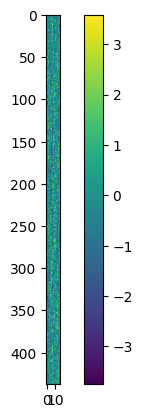

In [155]:
plt.imshow(model.embedding.weight.cpu().detach().numpy())
plt.colorbar()
plt.show()

In [156]:
sim_matrix.shape

torch.Size([438, 438])

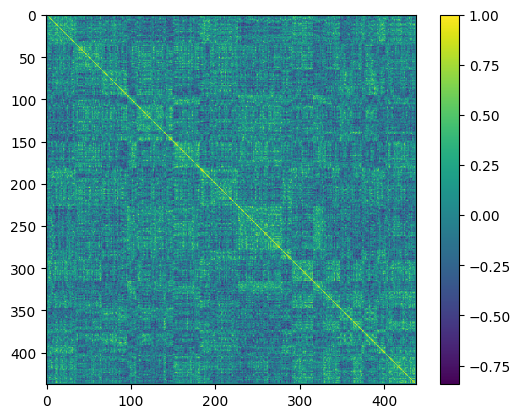

In [157]:
plt.imshow(sim_matrix.cpu().numpy())
plt.colorbar()
plt.show()

In [158]:
save_coss = True

In [159]:
if save_coss:

    token_ids = np.arange(sim_matrix.shape[0])

    coss = pd.DataFrame(
        sim_matrix.detach().cpu().numpy(),
        index=token_ids,
        columns=token_ids,
    )

    coss.to_csv(notebook_csv_path('bert_with_vis', "cosine_similarity_matrix_gpt_with_vis.csv"), index=True)

In [110]:
coss.head()

,0,1,2,3,4,5,6,7,8,9,...,428,429,430,431,432,433,434,435,436,437
0,1.000000,0.155473,0.126035,0.090161,-0.145506,0.272846,-0.000738,-0.513448,0.105055,-0.097626,...,0.057906,-0.269753,0.078368,-0.400995,-0.077626,-0.151993,-0.068844,-0.304000,-0.470922,0.0
1,0.155473,1.000000,-0.145478,0.054319,0.008239,0.412677,-0.164239,-0.342376,-0.242293,0.113026,...,0.199321,0.000102,0.230553,-0.444803,-0.082399,-0.332205,-0.029050,-0.464229,-0.051000,0.0
2,0.126035,-0.145478,1.000000,0.017834,0.130405,0.037043,0.361891,0.076625,-0.029789,-0.240390,...,0.205804,0.022126,-0.061155,0.055599,-0.119469,-0.024355,-0.283841,0.132884,-0.037967,0.0
3,0.090161,0.054319,0.017834,1.000000,0.435647,0.453846,0.474890,-0.147782,0.190047,0.003597,...,0.140632,-0.269280,0.482229,0.014090,0.345485,-0.220609,-0.163261,-0.388083,-0.118939,0.0
4,-0.145506,0.008239,0.130405,0.435647,1.000000,0.420834,0.224857,0.136799,-0.091010,0.076859,...,-0.048277,0.452038,0.581575,0.285566,0.378884,0.094068,0.174911,0.040919,0.328050,0.0


## vizz head projections

In [111]:
def _get_qk_head_mats(layer, embed_size: int, num_heads: int):
    attn = layer.self_attn
    E = embed_size
    H = num_heads
    Hd = E // H

    # in_proj_weight = [WQ; WK; WV]  -> (3E, E)
    W = attn.in_proj_weight.detach().cpu()
    Wq = W[:E, :]
    Wk = W[E:2*E, :]

    Wq_heads, Wk_heads = {}, {}
    for h in range(H):
        sl = slice(h*Hd, (h+1)*Hd)
        Wq_heads[h] = Wq[sl, :].contiguous()  # (Hd, E)
        Wk_heads[h] = Wk[sl, :].contiguous()  # (Hd, E)
    return Wq_heads, Wk_heads

@torch.no_grad()
def _embedding_matrix_np(model, dtype=np.float32):
    return model.embedding.weight.detach().cpu().numpy().astype(dtype)  # (V, E)

@torch.no_grad()
def cosine_matrix_per_head(model, layer_idx: int, num_heads: int,
                           use_positional: bool = False, pos_index: int = 0,
                           dtype=np.float32):
    """
    Retorna dict {h: M_h} onde M_h é (V, V) com cos(q_{h,i}, k_{h,j}).
    Linhas/colunas do PAD (se houver) são NaN.
    """
    E = _embedding_matrix_np(model, dtype=dtype)    # (V, D)
    V, D = E.shape
    layer = model.encoder.layers[layer_idx]
    Wq_heads, Wk_heads = _get_qk_head_mats(layer, D, num_heads)

    # entrada para Q/K: com ou sem posicional fixo
    if use_positional:
        pe = model.position_embedding.weight[pos_index].detach().cpu().numpy().astype(dtype)
        Ein = E + pe[None, :]
    else:
        Ein = E

    mats = {}
    pad_id = getattr(model, "pad_token_id", None)
    pad_id = int(pad_id) if pad_id is not None else None
    has_pad = pad_id is not None and 0 <= pad_id < V

    for h in range(num_heads):
        Wq = Wq_heads[h].numpy().astype(dtype)  # (Hd, D)
        Wk = Wk_heads[h].numpy().astype(dtype)  # (Hd, D)

        Qh = Ein @ Wq.T   # (V, Hd)
        Kh = Ein @ Wk.T   # (V, Hd)

        # normaliza por linha para cosseno
        Qn = np.linalg.norm(Qh, axis=1, keepdims=True) + 1e-12
        Kn = np.linalg.norm(Kh, axis=1, keepdims=True) + 1e-12
        Qh_hat = Qh / Qn
        Kh_hat = Kh / Kn

        M = Qh_hat @ Kh_hat.T            # (V, V)
        M = np.clip(M, -1.0, 1.0)

        if has_pad:
            M[pad_id, :] = np.nan
            M[:, pad_id] = np.nan

        mats[h] = M
    return mats


In [112]:
# parâmetros do seu modelo
layer_idx = 0

# 1) calcula as matrizes de similaridade por cabeça
mats_cos = cosine_matrix_per_head(model, layer_idx=layer_idx, num_heads=num_heads,
                                  use_positional=False, pos_index=0)

# 2) coloca cada cabeça em variáveis separadas
head0_cos = mats_cos[0]   # shape (V, V)
# head1_cos = mats_cos[1]   # shape (V, V)

head0_cos.shape#, head1_cos.shape

(438, 438)

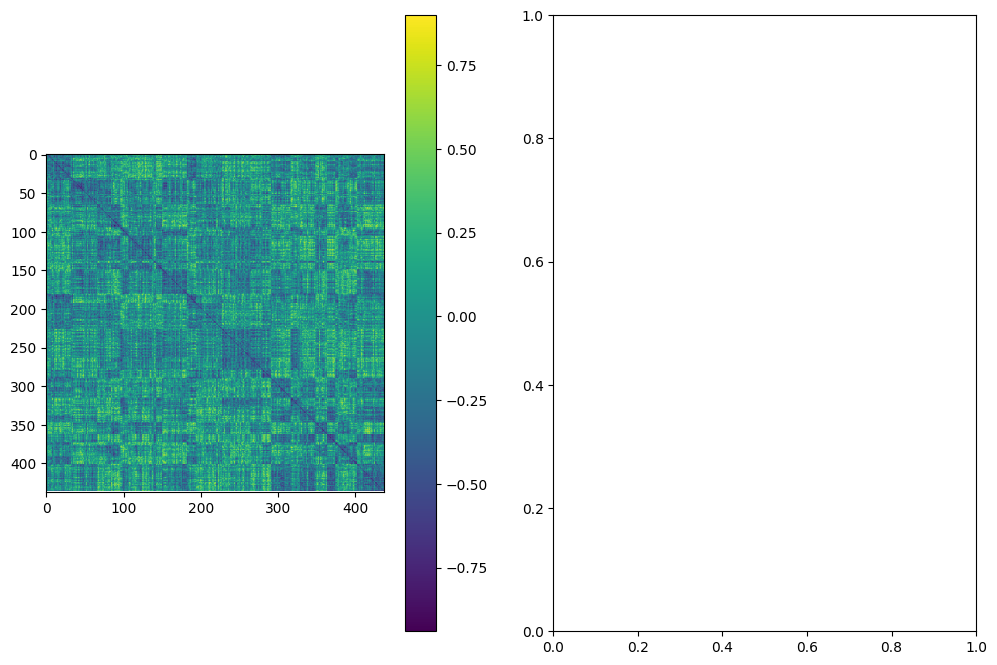

In [113]:
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
ax0 = ax[0].imshow(head0_cos)
plt.colorbar(ax0, )


# ax1 = ax[1].imshow(head1_cos)
# plt.colorbar(ax1, )
# plt.imshow(head1_cos, ax=ax[1])

plt.show()

In [114]:
save_heads = True

In [118]:
if save_heads:
    V = head0_cos.shape[0]
    cols = list(range(V))
    pd.DataFrame(head0_cos, index=cols, columns=cols).to_csv(notebook_csv_path('bert_with_vis', "head0_cosine_similarity_gpt_with_vis.csv"), index=False)
    # pd.DataFrame(head1_cos, index=cols, columns=cols).to_csv(notebook_csv_path('bert_with_vis', "head1_cosine_similarity_gpt.csv"), index=False)

## vizz attention

In [119]:
@torch.no_grad()
def token_token_attention_matrices_per_head(
    model,
    layer_idx: int,
    num_heads: int,
    use_positional: bool = False,
    pos_index: int = 0,
    dtype=np.float32,
):
    """
    Retorna dict {h: A_h} onde A_h é (V, V) com atenção pós-softmax por cabeça:
        A_h[i, j] = softmax_j( (q_{h,i} · k_{h,j}) / sqrt(head_dim) )
    Tratamento de PAD:
        - linha do PAD vira NaN (token inexistente como 'query');
        - coluna do PAD é mascarada no softmax (prob=0), e as linhas restantes são renormalizadas.
    """
    E = _embedding_matrix_np(model, dtype=dtype)  # (V, D)
    V, D = E.shape
    layer = model.encoder.layers[layer_idx]
    Wq_heads, Wk_heads = _get_qk_head_mats(layer, D, num_heads)

    # entrada Q/K: com ou sem posicional fixo
    if use_positional:
        pe = model.position_embedding.weight[pos_index].detach().cpu().numpy().astype(dtype)
        Ein = E + pe[None, :]
    else:
        Ein = E

    pad_id = getattr(model, "pad_token_id", None)
    pad_id = int(pad_id) if pad_id is not None else None
    has_pad = pad_id is not None and 0 <= pad_id < V

    mats = {}
    Hd = D // num_heads
    scale = 1.0 / np.sqrt(Hd)

    for h in range(num_heads):
        Wq = Wq_heads[h].numpy().astype(dtype)  # (Hd, D)
        Wk = Wk_heads[h].numpy().astype(dtype)  # (Hd, D)

        Qh = Ein @ Wq.T   # (V, Hd)
        Kh = Ein @ Wk.T   # (V, Hd)

        # logits = QK^T / sqrt(Hd)
        logits = (Qh @ Kh.T) * scale  # (V, V)

        if has_pad:
            # Mascarar coluna PAD no softmax (ninguém deve prestar atenção ao PAD)
            logits[:, pad_id] = -1e9
            # E a linha PAD inteira não é uma query válida
            logits[pad_id, :] = -1e9

        # softmax row-wise, numericamente estável
        m = np.max(logits, axis=1, keepdims=True)
        exps = np.exp(logits - m)
        # se linha foi toda -1e9 (caso PAD), soma ~0 -> trataremos já já
        sums = np.sum(exps, axis=1, keepdims=True)
        Ah = exps / np.clip(sums, 1e-12, None)

        if has_pad:
            # linha PAD vira NaN
            Ah[pad_id, :] = np.nan
            # coluna PAD fica ~0 (já ficou por masking)

        mats[h] = Ah.astype(dtype)

    return mats


In [120]:
# parâmetros do seu modelo
layer_idx = 0

attn_by_head = token_token_attention_matrices_per_head(
    model,
    layer_idx=layer_idx,
    num_heads=num_heads,
    use_positional=False,  # ligue se quiser aproximar a entrada do encoder em uma posição fixa
    pos_index=0,
)

# variáveis separadas por cabeça
head0_att = attn_by_head[0]   # (V, V) linhas somam 1 (exceto linha PAD = NaN)
# head1_att = attn_by_head[1]

head0_att.shape #, head1_att.shape

(438, 438)

In [121]:
save_att = True

In [122]:
if save_att:
    V = head0_att.shape[0]
    cols = list(range(V))
    pd.DataFrame(head0_att, index=cols, columns=cols).to_csv(notebook_csv_path('bert_with_vis', "head0_attention_softmax_gpt_with_vis.csv"), index=False)
    # pd.DataFrame(head1_att, index=cols, columns=cols).to_csv(notebook_csv_path('bert_with_vis', "head1_attention_softmax_gpt.csv"), index=False)

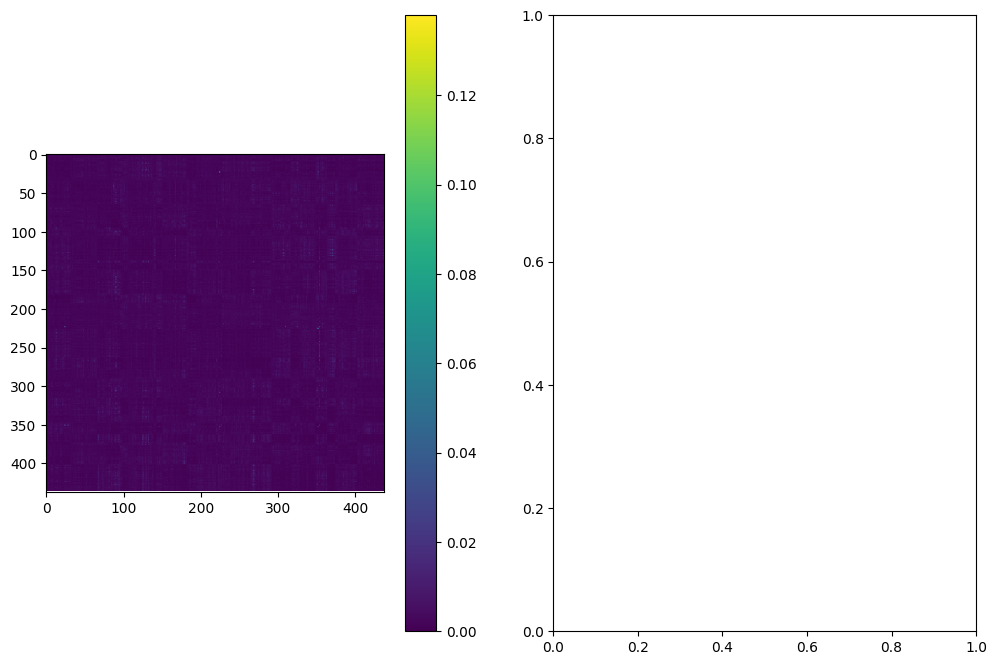

In [123]:
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
ax0 = ax[0].imshow(head0_att)
plt.colorbar(ax0, )


# ax1 = ax[1].imshow(head1_att)
# plt.colorbar(ax1, )
# plt.imshow(head1_cos, ax=ax[1])

plt.show()

## vizz heat attention w pos

In [124]:
@torch.no_grad()
def token_token_attention_matrices_per_head(
    model,
    layer_idx: int,
    num_heads: int,
    *,
    pos_i: int = 0,          # posição do token i (query)
    pos_j: int = 1,          # posição do token j (key)
    mode: str = "softmax",   # "cosine" | "logit" | "softmax"
    temperature: float = 1.0,
    dtype = np.float32,
):
    """
    Retorna dict {h: M_h} onde M_h é (V, V) com a métrica escolhida:
      - mode="cosine":   M_h[i,j] = cos(q_{h,i}^{pos_i}, k_{h,j}^{pos_j})
      - mode="logit":    M_h[i,j] = (q_{h,i}^{pos_i} · k_{h,j}^{pos_j}) / sqrt(d_h)
      - mode="softmax":  M_h[i,:] = softmax_j( logit(i,j) / temperature )

    Observações:
    - Inclui vieses b_Q e b_K do MultiheadAttention.
    - Análise é "token↔token" (V×V); no forward real, o softmax é sobre POSIÇÕES (T).
    - PAD: linha PAD vira NaN (query inválida) e coluna PAD é mascarada (prob=0).
    """
    assert mode in {"cosine", "logit", "softmax"}
    E_tok = model.embedding.weight.detach().cpu().numpy().astype(dtype)  # (V, D)
    V, D = E_tok.shape
    Hd = D // num_heads

    layer = model.encoder.layers[layer_idx]
    attn = layer.self_attn

    # Pesos e vieses (in_proj = [WQ; WK; WV], [bQ; bK; bV])
    W = attn.in_proj_weight.detach().cpu().numpy().astype(dtype)  # (3D, D)
    b = attn.in_proj_bias.detach().cpu().numpy().astype(dtype)    # (3D,)
    Wq_all, Wk_all = W[:D, :], W[D:2*D, :]
    bq_all, bk_all = b[:D],     b[D:2*D]

    # Fatia por cabeça
    Wq_heads, Wk_heads, bq_heads, bk_heads = {}, {}, {}, {}
    for h in range(num_heads):
        sl = slice(h*Hd, (h+1)*Hd)
        Wq_heads[h] = Wq_all[sl, :].copy()  # (Hd, D)
        Wk_heads[h] = Wk_all[sl, :].copy()  # (Hd, D)
        bq_heads[h] = bq_all[sl].copy()     # (Hd,)
        bk_heads[h] = bk_all[sl].copy()     # (Hd,)

    # Embeddings com posicionais distintos para Q e K
    pe_i = model.position_embedding.weight[pos_i].detach().cpu().numpy().astype(dtype)  # (D,)
    pe_j = model.position_embedding.weight[pos_j].detach().cpu().numpy().astype(dtype)  # (D,)
    Ein_Q = E_tok + pe_i[None, :]   # (V, D)
    Ein_K = E_tok + pe_j[None, :]   # (V, D)

    # PAD handling
    pad_id = getattr(model, "pad_token_id", None)
    pad_id = int(pad_id) if pad_id is not None else None
    has_pad = pad_id is not None and 0 <= pad_id < V

    mats = {}
    scale = 1.0 / np.sqrt(Hd)

    for h in range(num_heads):
        Wq_h, Wk_h = Wq_heads[h], Wk_heads[h]
        bq_h, bk_h = bq_heads[h], bk_heads[h]

        # Projeções por cabeça, com vieses
        Qh = Ein_Q @ Wq_h.T;  Qh += bq_h[None, :]    # (V, Hd)
        Kh = Ein_K @ Wk_h.T;  Kh += bk_h[None, :]    # (V, Hd)

        if mode == "cosine":
            # cos(q,k) = (Qh/||Qh||) @ (Kh/||Kh||)^T
            Qn = np.linalg.norm(Qh, axis=1, keepdims=True) + 1e-12
            Kn = np.linalg.norm(Kh, axis=1, keepdims=True) + 1e-12
            Qh_hat = Qh / Qn
            Kh_hat = Kh / Kn
            M = Qh_hat @ Kh_hat.T
            M = np.clip(M, -1.0, 1.0)

        else:
            # logits = (Qh @ Kh^T) / sqrt(Hd)
            logits = (Qh @ Kh.T) * scale

            if mode == "logit":
                M = logits
            else:
                # mode == "softmax"
                if has_pad:
                    logits[:, pad_id] = -1e9   # ninguém deve prestar atenção ao PAD
                    logits[pad_id, :] = -1e9   # PAD como query não é válido

                # temperatura
                L = logits / max(temperature, 1e-8)

                # softmax por linha (estável)
                m = np.max(L, axis=1, keepdims=True)
                exps = np.exp(L - m)
                sums = np.sum(exps, axis=1, keepdims=True)
                M = exps / np.clip(sums, 1e-12, None)

        if has_pad:
            # Linha PAD = NaN (query inválida); para cosine/logit isso evita leituras enganosas
            M[pad_id, :] = np.nan
            # Para cosine/logit, pode ser útil também mascarar a coluna PAD:
            M[:, pad_id] = np.nan if mode != "softmax" else M[:, pad_id]

        mats[h] = M.astype(dtype)

    return mats


In [125]:
# parâmetros (ajuste se quiser)
layer_idx   = 0
pos_i       = 0      # posição do token i (query)
pos_j       = 1      # posição do token j (key)
# temperature = 1.0    # só usado quando mode="softmax"

modes = ["cosine", "logit", "softmax"]

In [126]:
for mode in modes:
    mats = token_token_attention_matrices_per_head(
        model,
        layer_idx=layer_idx,
        num_heads=num_heads,
        pos_i=pos_i,
        pos_j=pos_j,
        mode=mode,
        # temperature=temperature,
        dtype=np.float32,
    )

    for h in range(num_heads):
        M = mats[h]  # (V, V)
        V = M.shape[0]
        ids = list(range(V))
        dfto_to_to = pd.DataFrame(M, index=ids, columns=ids)
        # nome do arquivo: head{h}_{mode}_pos{pos_i}_to_pos{pos_j}.csv
        fname = f"head{h}_{mode}_pos{pos_i}_to_pos{pos_j}_gpt_with_vis.csv"
        dfto_to_to.to_csv(notebook_csv_path('bert_with_vis', fname), index=False)
        print(f"salvo: {fname}")


salvo: head0_cosine_pos0_to_pos1_gpt_with_vis.csv
salvo: head0_logit_pos0_to_pos1_gpt_with_vis.csv
salvo: head0_softmax_pos0_to_pos1_gpt_with_vis.csv


## vizz generate

In [127]:
@torch.no_grad()
def next_token_preview(model, dataloader, i: int = 0, top_k: int = 10,
                       id_to_token=None, device=None):
    """
    Mostra só o último passo válido (AR): prompt, alvo e top-k do próximo token.
    Retorna um dicionário com tudo que foi calculado.
    """
    if id_to_token is None: id_to_token = {}
    if device is None: device = next(model.parameters()).device

    x_batch, y_batch, attn_batch = next(iter(dataloader))
    b = i % x_batch.size(0)
    x, y, attn = x_batch[b].to(device), y_batch[b].to(device), attn_batch[b].to(device)

    T_valid = int(attn.sum().item())
    if T_valid < 1:
        print("Exemplo sem tokens válidos."); return {}

    model.eval()
    logits = model(x.unsqueeze(0), attention_mask=attn.unsqueeze(0))  # [1, T, V]
    last_logits = logits[0, T_valid - 1]                              # [V]
    probs = torch.softmax(last_logits, dim=-1)
    pred_id = int(torch.argmax(probs).item())
    gold_id = int(y[T_valid - 1].item())
    has_gold = (gold_id != -100)

    def t2s(t): return id_to_token.get(int(t), str(int(t)))
    prompt_ids = x[:T_valid].tolist()

    k = min(top_k, last_logits.numel()) if top_k and top_k > 0 else 0
    top_ids, top_ps = ([], [])
    if k:
        vals, idxs = torch.topk(probs, k=k)
        top_ids = idxs.tolist(); top_ps = vals.tolist()

    # prints curtos
    print("\n=== Próximo token (AR) ===")
    print("Input:", "[" + " ".join(t2s(t) for t in prompt_ids) + "]")
    print("Alvo:", t2s(gold_id) if has_gold else "-",
          "| Pred:", t2s(pred_id),
          "| Correto?:", "SIM" if has_gold and pred_id == gold_id else "—")
    if has_gold:
        print(f"p(gold)={probs[gold_id].item():.4f}  p(pred)={probs[pred_id].item():.4f}")
    if k:
        print(f"Top-{k}: " + ", ".join(f"{t2s(t)}({p:.3f})" for t, p in zip(top_ids, top_ps)))

    return {
        "prompt_ids": prompt_ids,
        "gold_id": None if not has_gold else gold_id,
        "pred_id": pred_id,
        "topk_ids": top_ids,
        "topk_probs": top_ps,
    }

In [128]:
_ = next_token_preview(model, val_loader, i=0, top_k=3,)


=== Próximo token (AR) ===
Input: [18 214 291 26 18 218 291 214 2]
Alvo: 214 | Pred: 26 | Correto?: —
p(gold)=0.1277  p(pred)=0.1695
Top-3: 26(0.170), 214(0.128), 392(0.127)


In [129]:
model.generate(torch.tensor([15]), max_new_tokens=10)

tensor([ 15, 209, 194, 214,  26,  26, 280, 216, 218, 398, 280],
       device='cuda:0')

## vizz regions

In [47]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    df_to_apd_ps_id_dict,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    
    # Remove duplicados preservando a ordem
    ordem_unica = [df_to_apd_ps_id_dict[k] for k in dict.fromkeys(grupos_destacados)]
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = plt.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="best")

    # Não chama plt.show(); quem usa decide salvar/mostrar

## vizz distribuitions

In [62]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.30,"[0.43, 0.995]",0.024639,"[0.012446556790744653, 0.07959584984652546]",7.260726,"[0.15449447585045925, 0.9879936522729749]",AAAAAAAAAAAAAAAAAAAA,1,0.003165,213.0,1
1,0.45,"[0.443, 0.995]",0.037561,"[0.08614574461037638, 0.000395365395139032]",-9.407193,"[0.9999894684378726, 0.004589445864238177]",NFTUXYCOAAAAAAAAAAAA,213,0.674051,1.0,1
2,0.60,"[0.456, 0.994]",0.050044,"[0.08308661025307733, -0.004641886637031245]",-0.402658,"[0.9984430244912736, -0.05578106170303712]",NFTUXYCOAOWPAAAAAAAA,214,0.677215,213.0,1
3,0.75,"[0.464, 0.986]",0.061659,"[0.05364264840851248, -0.05584120397332434]",-4.997719,"[0.6927676379110387, -0.7211608696145125]",MOWWAOWPAAAAAAAAAAAA,145,0.458861,214.0,1
4,0.90,"[0.47, 0.981]",0.069760,"[0.04175660961639498, -0.03425926211447846]",0.789277,"[0.7730967157124784, -0.6342881586113518]",AOWPAAAAAAAAAAAAAAAA,2,0.006329,145.0,1


In [64]:
df[df['position_state_id'] == 160]

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
156,27.45,"[0.806, 0.898]",2.918023,"[-0.04983662287434336, 0.009444024990856725]",-6.238867,"[-0.9825144782792598, 0.1861861970491744]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,8.0,1
158,27.75,"[0.791, 0.892]",2.936226,"[-0.07145098054399743, 0.003976492096517219]",-7.140535,"[-0.9984549361263646, 0.055567441230428866]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,8.0,1
195,33.30,"[0.692, 0.723]",3.432428,"[-0.05335618162257768, 0.04531923597975644]",-5.345964,"[-0.7621755395860218, 0.6473704093150661]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,144.0,1
204,34.80,"[0.522, 0.688]",3.706468,"[-0.11652459794874023, 0.2902298333687751]",-11.188224,"[-0.3725829808790337, 0.9279988805808408]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,81.0,1
210,35.70,"[0.508, 0.697]",3.799496,"[-0.003048473041749785, 0.03223314476494007]",-16.642281,"[-0.09415557218475643, 0.9955574961932439]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,25.0,1
...,...,...,...,...,...,...,...,...,...,...,...
4516,823.50,"[0.718, 0.798]",79.028603,"[-0.06522393000856219, 0.022356030296876533]",-3.533792,"[-0.9459746864395906, 0.3242404857748614]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,144.0,1
4555,832.95,"[0.259, 0.862]",80.217746,"[0.11079920287492051, 0.02316567089802879]",3.437530,"[0.9788346405141751, 0.2046527462055802]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,144.0,1
4609,842.25,"[0.707, 0.77]",80.942796,"[-0.046562157833615433, 0.02760654366591601]",3.157472,"[-0.8601768348488907, 0.5099958948749921]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,207.0,1
4739,865.80,"[0.22, 0.793]",83.547065,"[0.09420574860844837, 0.056166303574873844]",-8.653256,"[0.8589261836073215, 0.5120994152640304]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,287.0,1


In [67]:
df.iloc[150:161]

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
150,26.40,"[0.86, 0.917]",2.856435,"[-0.06386078223352169, 0.039051503020153255]",-5.192330,"[-0.8531304047428361, 0.5216977213898147]",XYCONFTUAAAAAAAAAAAA,291,0.920886,13.0,1
151,26.55,"[0.851, 0.912]",2.866727,"[-0.06084359784771658, -0.03170820089010078]",6.861812,"[-0.8868016349833187, -0.46215025715768343]",AOWPMOWWAAAAAAAAAAAA,8,0.025316,291.0,1
152,26.70,"[0.845, 0.911]",2.872687,"[-0.03906389525512773, -0.007262070334765151]",-1.977443,"[-0.9831555249037873, -0.18277093273044895]",NFTUMOWWAAAAAAAAAAAA,211,0.667722,8.0,1
153,26.85,"[0.844, 0.908]",2.876276,"[-0.0089474472520464, -0.022192754881601072]",6.691936,"[-0.3739236092437601, -0.927459505558124]",AOWPAAAAAAAAAAAAAAAA,2,0.006329,211.0,1
154,27.00,"[0.834, 0.907]",2.886385,"[-0.06719474038408668, -0.005125583542189283]",-7.409773,"[-0.9971033509295121, -0.07605857982593583]",NFTUMOWWAAAAAAAAAAAA,211,0.667722,2.0,1
155,27.30,"[0.813, 0.896]",2.910414,"[-0.051759888609924275, -0.048078143018952524]",3.236760,"[-0.7326848593506883, -0.6805680692467595]",AOWPMOWWAAAAAAAAAAAA,8,0.025316,211.0,1
156,27.45,"[0.806, 0.898]",2.918023,"[-0.04983662287434336, 0.009444024990856725]",-6.238867,"[-0.9825144782792598, 0.1861861970491744]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,8.0,1
157,27.60,"[0.802, 0.891]",2.925492,"[-0.026251234415897905, -0.04230910886161787]",8.018440,"[-0.5272237908541819, -0.8497264703169755]",AOWPMOWWAAAAAAAAAAAA,8,0.025316,160.0,1
158,27.75,"[0.791, 0.892]",2.936226,"[-0.07145098054399743, 0.003976492096517219]",-7.140535,"[-0.9984549361263646, 0.055567441230428866]",MOWWNFTUAAAAAAAAAAAA,160,0.506329,8.0,1
159,27.90,"[0.79, 0.88]",2.947941,"[-0.010226995138270894, -0.0774256812790508]",9.967188,"[-0.13095047288640588, -0.991388911401992]",AOWPAAAAAAAAAAAAAAAA,2,0.006329,160.0,1


In [130]:
tokens, d = model.generate_with_distributions(
    torch.tensor([211, 2, 211, 8, 160]),
    max_new_tokens=10,
    temperature=1.0,
    top_k=None,
    return_logits=True,
    return_raw_logits=True,
)
tokens

tensor([211,   2, 211,   8, 160,   8, 389,  26, 390, 214, 392, 390, 194,   1,
        287], device='cuda:0')

In [131]:
len(d['probs'])

10

In [132]:
distribs_probs = pd.DataFrame()
for i in range(len(d['probs'])):
    distribs_probs[f'Passo {i+1:02d}'] = d['probs'][i, :]

In [133]:
distribs_probs.head(2)

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,3.544968e-18,8.278351e-17,1.451552e-15,8.300044e-16,1.728383e-16,8.483308e-14,8.483308e-14,8.483308e-14,8.483308e-14,8.483308e-14
1,6.599455e-03,1.034740e-02,2.160325e-02,3.195591e-02,3.292986e-02,2.009334e-01,2.009334e-01,2.009334e-01,2.009334e-01,2.009334e-01


In [134]:
distribs_probs.to_csv(notebook_csv_path('bert_with_vis', 'gpt_probs_distribs_160_with_vis.csv'), index=False)

In [135]:
distribs_logits = pd.DataFrame()
for i in range(len(d['logits'])):
    distribs_logits[f'Passo {i+1:02d}'] = d['logits'][i, :]

In [136]:
distribs_logits.to_csv(notebook_csv_path('bert_with_vis', 'gpt_logits_distribs_160_with_vis.csv'), index=False)

In [137]:
distribs_logits_raw = pd.DataFrame()
for i in range(len(d['logits_raw'])):
    distribs_logits_raw[f'Passo {i+1:02d}'] = d['logits_raw'][i, :]

In [138]:
distribs_logits_raw.to_csv(notebook_csv_path('bert_with_vis', 'gpt_logits_raw_distribs_160_with_vis.csv'), index=False)

In [139]:
# d['logits_raw']

In [140]:
# pd.DataFrame(d, index=range(len(d)))

In [141]:
# apd.head()

## weigths

In [49]:
@torch.no_grad()
def attention_weight_summaries(model):
    """
    Retorna dicionário com tensores (CPU) dos pesos de atenção por camada:
    - Wq, Wk, Wv, Wout (e biases).
    """
    attn_weights = []  # lista por camada
    # O TransformerEncoder guarda as camadas em model.encoder.layers
    for layer in model.encoder.layers:
        attn = layer.self_attn  # nn.MultiheadAttention
        # in_proj_weight empilha [Wq; Wk; Wv] com shape (3*E, E)
        in_w = attn.in_proj_weight.detach().cpu()            # [3E, E]
        E = in_w.shape[1]
        Wq, Wk, Wv = in_w[:E], in_w[E:2*E], in_w[2*E:3*E]

        in_b = attn.in_proj_bias.detach().cpu() if attn.in_proj_bias is not None else None
        if in_b is not None:
            bq, bk, bv = in_b[:E], in_b[E:2*E], in_b[2*E:3*E]
        else:
            bq = bk = bv = None

        Wout = attn.out_proj.weight.detach().cpu()          # [E, E]
        bout = attn.out_proj.bias.detach().cpu() if attn.out_proj.bias is not None else None

        attn_weights.append({
            "Wq": Wq, "Wk": Wk, "Wv": Wv, "Wout": Wout,
            "bq": bq, "bk": bk, "bv": bv, "bout": bout
        })
    return attn_weights

def plot_layerwise_norms(attn_weights):
    """
    Faz um gráfico de linhas com normas L2 de Wq, Wk, Wv e Wout por camada.
    """
    Wq_norms, Wk_norms, Wv_norms, Wout_norms = [], [], [], []
    for w in attn_weights:
        Wq_norms.append(torch.linalg.norm(w["Wq"]).item())
        Wk_norms.append(torch.linalg.norm(w["Wk"]).item())
        Wv_norms.append(torch.linalg.norm(w["Wv"]).item())
        Wout_norms.append(torch.linalg.norm(w["Wout"]).item())

    layers = list(range(len(attn_weights)))
    plt.figure()
    plt.plot(layers, Wq_norms, marker="o", label="‖Wq‖₂")
    plt.plot(layers, Wk_norms, marker="o", label="‖Wk‖₂")
    plt.plot(layers, Wv_norms, marker="o", label="‖Wv‖₂")
    plt.plot(layers, Wout_norms, marker="o", label="‖Wout‖₂")
    plt.xlabel("Camada do Encoder (0-index)")
    plt.ylabel("Norma L2")
    plt.title("Normas dos pesos de atenção por camada")
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_weight_histogram(attn_weights, layer_idx=0, which="Wq", bins=80):
    """
    Histograma dos valores dos pesos (Wq/Wk/Wv/Wout) de uma camada.
    """
    w = attn_weights[layer_idx][which].flatten()
    plt.figure()
    plt.hist(w.numpy(), bins=bins)
    plt.xlabel("Valor do peso")
    plt.ylabel("Frequência")
    plt.title(f"Histograma de {which} — Camada {layer_idx}")
    plt.tight_layout()
    plt.show()

def plot_weight_heatmap(attn_weights, layer_idx=0, which="Wq"):
    """
    Heatmap simples (imshow) do peso selecionado (Wq/Wk/Wv/Wout) de uma camada.
    Obs: para matrizes grandes, é só para ter noção de padrão/estruturas.
    """
    w = attn_weights[layer_idx][which]
    plt.figure()
    plt.imshow(w.numpy(), aspect="auto")
    plt.colorbar()
    plt.xlabel("Dimensão de entrada")
    plt.ylabel("Linhas da matriz")
    plt.title(f"Heatmap de {which} — Camada {layer_idx}")
    plt.tight_layout()
    plt.show()


In [126]:
vars(model)

{'training': False,
 '_parameters': OrderedDict(),
 '_buffers': OrderedDict(),
 '_non_persistent_buffers_set': set(),
 '_backward_pre_hooks': OrderedDict(),
 '_backward_hooks': OrderedDict(),
 '_is_full_backward_hook': None,
 '_forward_hooks': OrderedDict(),
 '_forward_hooks_with_kwargs': OrderedDict(),
 '_forward_hooks_always_called': OrderedDict(),
 '_forward_pre_hooks': OrderedDict(),
 '_forward_pre_hooks_with_kwargs': OrderedDict(),
 '_state_dict_hooks': OrderedDict(),
 '_state_dict_pre_hooks': OrderedDict(),
 '_load_state_dict_pre_hooks': OrderedDict(),
 '_load_state_dict_post_hooks': OrderedDict(),
 '_modules': OrderedDict([('embedding', Embedding(948, 16, padding_idx=947)),
              ('position_embedding', Embedding(10, 16)),
              ('encoder',
               TransformerEncoder(
                 (layers): ModuleList(
                   (0): TransformerEncoderLayer(
                     (self_attn): MultiheadAttention(
                       (out_proj): NonDynamicallyQ

In [141]:
model.encoder.layers[0]

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
  )
  (linear1): Linear(in_features=16, out_features=32, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (linear2): Linear(in_features=32, out_features=16, bias=True)
  (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
  (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (dropout2): Dropout(p=0.2, inplace=False)
)

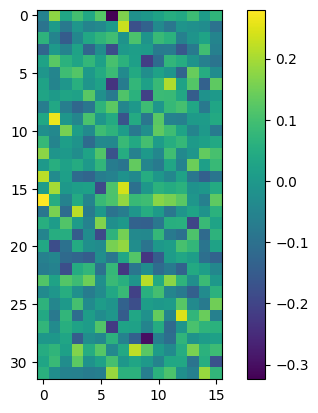

In [142]:
plt.imshow(model.encoder.layers[0].linear1.weight.cpu().detach().numpy())
plt.colorbar()

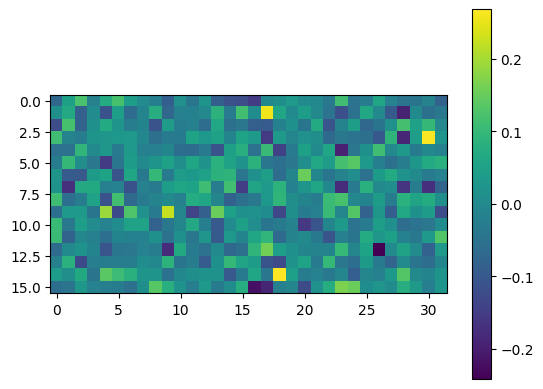

In [143]:
plt.imshow(model.encoder.layers[0].linear2.weight.cpu().detach().numpy())
plt.colorbar()

In [158]:
model.position_embedding.weight

Parameter containing:
tensor([[ 3.2782e-01, -1.4617e-01,  1.9067e-01, -1.1984e-01,  1.1580e-01,
         -1.0532e-01, -2.5150e-01, -4.1858e-02, -2.8337e-01, -6.4869e-02,
         -6.6963e-03, -1.0057e-01,  4.7451e-02,  1.2691e-01, -7.2445e-02,
          2.5352e-02],
        [ 1.7593e-01, -3.6490e-01,  2.4765e-05, -3.3846e-01, -8.1357e-02,
         -3.0092e-01, -4.7356e-01, -2.3471e-01, -4.8736e-01, -2.4879e-01,
         -1.8774e-01, -3.0559e-01, -1.2455e-01, -4.4149e-02, -2.7677e-01,
         -1.5246e-01],
        [ 3.5648e-01, -1.6150e-01,  1.9968e-01, -1.3950e-01,  1.1447e-01,
         -1.0114e-01, -2.7266e-01, -3.6082e-02, -2.9251e-01, -5.4839e-02,
         -7.1171e-04, -1.0776e-01,  6.4017e-02,  1.4480e-01, -8.8654e-02,
          3.6489e-02],
        [ 8.6687e-01,  3.3279e-01,  7.0166e-01,  3.4479e-01,  6.0547e-01,
          3.8809e-01,  2.1576e-01,  4.4952e-01,  2.0076e-01,  4.3074e-01,
          4.9281e-01,  3.7322e-01,  5.6521e-01,  6.3949e-01,  4.0212e-01,
          5.1888e-01]

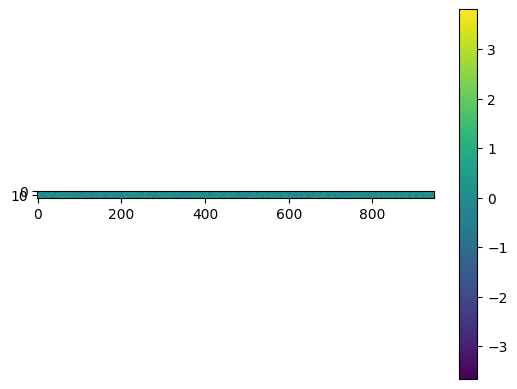

In [161]:
plt.imshow(model.embedding.weight.cpu().detach().numpy().reshape(embed_size, vocab_size))
plt.colorbar()

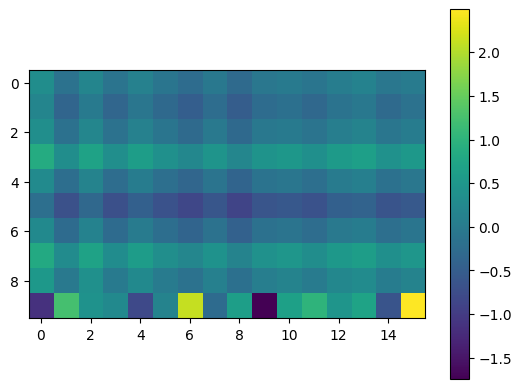

In [159]:
plt.imshow(model.position_embedding.weight.cpu().detach().numpy())
plt.colorbar()

In [154]:
vars(model.encoder.layers[0].self_attn)

{'training': False,
 '_parameters': OrderedDict([('in_proj_weight',
               Parameter containing:
               tensor([[ 4.2750e-02, -3.3401e-03,  4.4392e-01, -3.8941e-01,  9.2374e-02,
                         8.1987e-02,  9.8693e-02, -9.8778e-02, -1.5338e-01, -8.3268e-02,
                        -5.3662e-01,  8.4517e-02,  1.5088e-01,  1.2205e-01,  1.6315e-01,
                        -2.3023e-01],
                       [ 9.4586e-02, -1.6190e-01, -4.5145e-01, -1.0679e-01, -5.6028e-01,
                         6.4482e-02,  2.1682e-01, -4.2140e-01,  2.5964e-01,  2.0489e-01,
                         5.5536e-02,  1.2062e-01, -9.9174e-02,  4.1799e-01, -1.7419e-01,
                        -3.7785e-01],
                       [ 4.8718e-02,  7.3677e-02, -1.9097e-02,  1.2027e-01,  1.9135e-01,
                        -7.9686e-02,  3.5985e-01,  4.7477e-01, -2.1843e-01,  2.9956e-01,
                         3.1732e-02, -2.0651e-01, -1.1203e-01,  1.9271e-01,  5.4177e-03,
                  

In [ ]:
plt.imshow(model.encoder.linear1.weight.cpu().detach().numpy())

IndexError: index 1 is out of range

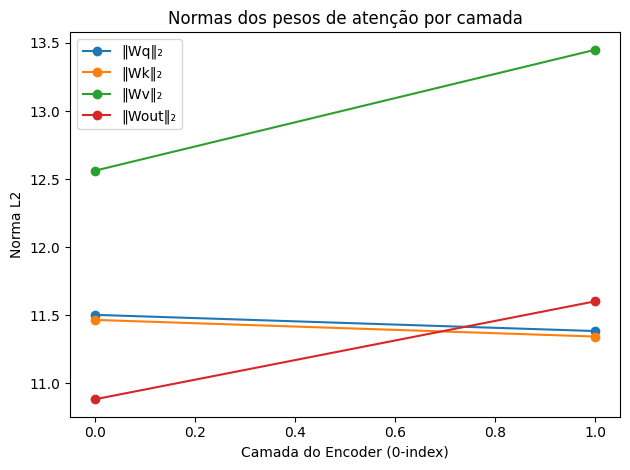

In [74]:
# 1) Coletar pesos de atenção
attn_ws = attention_weight_summaries(model)

# 2) Gráfico de linhas com normas por camada (Q, K, V e out)
plot_layerwise_norms(attn_ws)

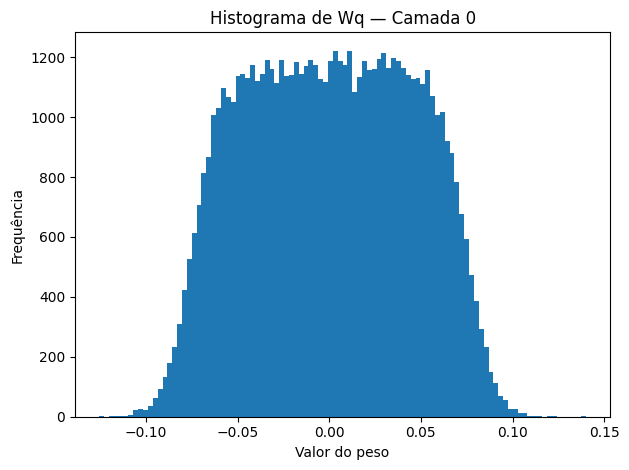

In [75]:
# 3) Histograma dos pesos de Wq da camada 0 (mude o índice/which se quiser)
plot_weight_histogram(attn_ws, layer_idx=0, which="Wq", bins=100)

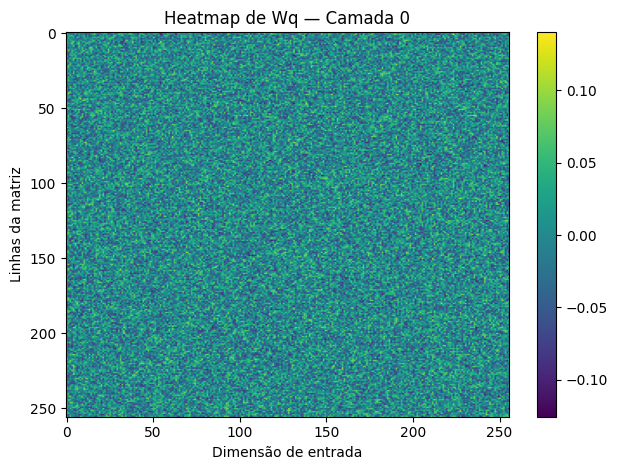

In [76]:

# 4) Heatmap de Wq da camada 0
plot_weight_heatmap(attn_ws, layer_idx=0, which="Wq")

In [ ]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = plt.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="best")

    # Não chama plt.show(); quem usa decide salvar/mostrar


In [81]:
def gerar_graficos_expansao(apd, sequencias_ids, pasta_destino="imgs", titulo_base="Passo", dpi=150):
    """
    Gera e salva gráficos por etapas, pintando as regiões em função da lista de ids recebida.
    NÃO executa modelo; apenas plota conforme as sequências fornecidas.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - sequencias_ids: lista de listas de ids (ex.: [[s,e], [s,x,e], [s,x,y,e], ...])
                      Cada sublista é um "passo" do GIF.
    - pasta_destino: pasta onde os PNGs serão salvos
    - titulo_base: prefixo do título (ex.: "Passo")
    - dpi: resolução dos PNGs

    Retorna:
    - lista com os caminhos dos arquivos gerados
    """
    if not isinstance(sequencias_ids, (list, tuple)) or len(sequencias_ids) == 0:
        raise ValueError("sequencias_ids deve ser uma lista não vazia de listas de ids.")

    os.makedirs(pasta_destino, exist_ok=True)
    caminhos = []

    for step, ids in enumerate(sequencias_ids):
        if not isinstance(ids, (list, tuple)) or len(ids) == 0:
            raise ValueError(f"Item na posição {step} de sequencias_ids não é uma lista/tupla válida de ids.")

        caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")

        # usa a função definida antes no chat (com viridis, ordem por ids,
        # último em destaque, anotações pretas)
        title = f"{titulo_base} {step:02} | {ids[0]}->{ids[-1]}" if len(ids) >= 2 else f"{titulo_base} {step:02}"
        plot_position_states_w_title(apd, grupos_destacados=list(ids), title=title)

        plt.savefig(caminho_arquivo, bbox_inches="tight", dpi=dpi)
        plt.close()
        caminhos.append(caminho_arquivo)

    return caminhos


In [32]:
def expand_trajectory(model, start_token, end_token, mask_token_id, max_len=12, id_to_token=None):
    """
    Expande uma sequência entre start_token e end_token, preenchendo iterativamente
    tokens intermediários e mostrando o histórico de predições.
    """
    device = next(model.parameters()).device
    sequence = [start_token, end_token]
    step = 1

    while len(sequence) < max_len:
        print(f"\n=== Etapa {step} ===")
        print("Sequência atual:", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Inserção de MASKs entre os pares
        new_sequence = []
        for i in range(len(sequence) - 1):
            new_sequence.append(sequence[i])
            new_sequence.append(mask_token_id)
        new_sequence.append(sequence[-1])
        sequence = new_sequence

        print("Com [MASK]:     ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Predição
        input_tensor = torch.tensor(sequence, dtype=torch.long).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(input_tensor)
            predictions = torch.argmax(logits, dim=-1).squeeze(0).cpu().tolist()
            print('Predição Completa', predictions)

        # Substituição dos MASKs e exibição
        updated_sequence = []
        for i, token in enumerate(sequence):
            if token == mask_token_id:
                predicted_token = predictions[i]
                updated_sequence.append(predicted_token)
                print(f"Predição na posição {i}: {id_to_token.get(predicted_token, predicted_token) if id_to_token else predicted_token}")
            else:
                updated_sequence.append(token)

        sequence = updated_sequence
        print("Após predição: ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        if len(sequence) >= max_len:
            print("\nLimite de comprimento atingido.")
            break

        step += 1

    print("\n=== Trajetória Final ===")
    print([id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])
    return sequence


In [33]:
np.random.choice(sequences, 2)

array([507, 715])

In [34]:
start_token = 507
end_token = 715
# max_len = 15

In [35]:
expand_trajectory(
    model,
    start_token=start_token,
    end_token=end_token,
    mask_token_id=mask_token_id,
    # max_len=max_len,
    # id_to_token=id_to_token  # ou None
)


=== Etapa 1 ===
Sequência atual: [507, 715]
Com [MASK]:      [507, 953, 715]
Predição Completa [799, 501, 582]
Predição na posição 1: 501
Após predição:  [507, 501, 715]

=== Etapa 2 ===
Sequência atual: [507, 501, 715]
Com [MASK]:      [507, 953, 501, 953, 715]
Predição Completa [332, 583, 583, 340, 716]
Predição na posição 1: 583
Predição na posição 3: 340
Após predição:  [507, 583, 501, 340, 715]

=== Etapa 3 ===
Sequência atual: [507, 583, 501, 340, 715]
Com [MASK]:      [507, 953, 583, 953, 501, 953, 340, 953, 715]
Predição Completa [507, 501, 507, 507, 507, 507, 507, 501, 330]
Predição na posição 1: 501
Predição na posição 3: 507
Predição na posição 5: 507
Predição na posição 7: 501
Após predição:  [507, 501, 583, 507, 501, 507, 340, 501, 715]

=== Etapa 4 ===
Sequência atual: [507, 501, 583, 507, 501, 507, 340, 501, 715]
Com [MASK]:      [507, 953, 501, 953, 583, 953, 507, 953, 501, 953, 507, 953, 340, 953, 501, 953, 715]
Predição Completa [507, 583, 340, 507, 507, 501, 507, 34

[507,
 583,
 501,
 507,
 583,
 501,
 507,
 340,
 501,
 507,
 507,
 501,
 340,
 507,
 501,
 501,
 715]

In [48]:
# apd = pd.read_parquet(r'legacy/datasets/apd_full.gzip')
# apd.shape

In [43]:
df_ps_to_apd_id = {ps:idx for ps, idx in zip(df['position_state'], df['position_state_id'])}

In [46]:
df['position_state_id'].max()

953

In [48]:
count = 0
current_max_id = df['position_state_id'].max() + 1
for apd_ps in apd['position_state'].unique():
    if apd_ps not in df_ps_to_apd_id:
        df_ps_to_apd_id[apd_ps]  = current_max_id
        current_max_id+=1
        count+=1
print(count)

0


In [50]:
apd['position_state_id'] = [df_ps_to_apd_id[ps] for ps in apd['position_state']]

In [55]:
apd['position_state_id'].nunique()

1057

In [49]:
# x_batch, y_batch = next(iter(val_loader))
# example_x = x_batch[0]
# example_y = y_batch[0]

# visualize_predictions(model, example_x, example_y, mask_token_id)

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


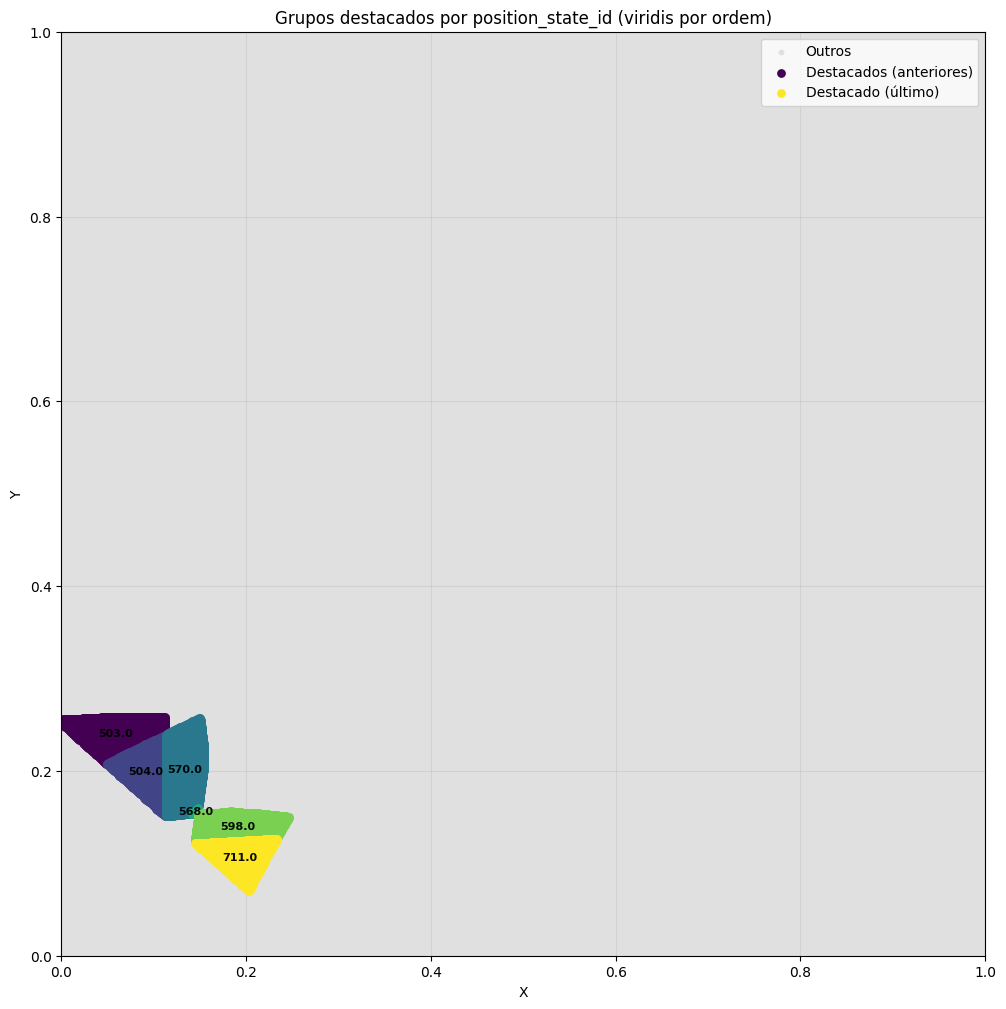

In [85]:
plot_position_states_w_title(apd, [503, 504, 570, 568, 598, 711])

In [ ]:
def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()

In [ ]:
def plot_position_states_w_region(apd, region):
    """
    Plota os pontos do DataFrame apd, destacando grupos (position_state_id)
    que possuem pontos dentro da região [xmin, xmax, ymin, ymax].

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y', 'position_state_id'
    - region: lista ou tupla com [xmin, xmax, ymin, ymax]
    """
    xmin, xmax, ymin, ymax = region

    # Filtrar os pontos que estão dentro da região
    dentro = apd[(apd['X'] >= xmin) & (apd['X'] <= xmax) &
                 (apd['Y'] >= ymin) & (apd['Y'] <= ymax)]

    # Identificar os grupos que têm pelo menos um ponto na região
    grupos_destacados = dentro['position_state_id'].unique()
    print('Grupos Destados', grupos_destacados)

    # Máscara dos grupos destacados
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Plot
    plt.figure(figsize=(12, 12))

    # Pontos não destacados (fundo)
    cor_base = '#e0e0e0'
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Pontos destacados (na região)
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar centro de massa de cada grupo destacado
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Colorbar
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Desenhar a região no gráfico
    plt.plot([xmin, xmax, xmax, xmin, xmin],
             [ymin, ymin, ymax, ymax, ymin], color='black', linestyle='--', linewidth=1.2, label='Região')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por interseção com região')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()

Grupos Destados [891 892 902 899]


/home/mgteus/workspace/navitrans/.nav/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


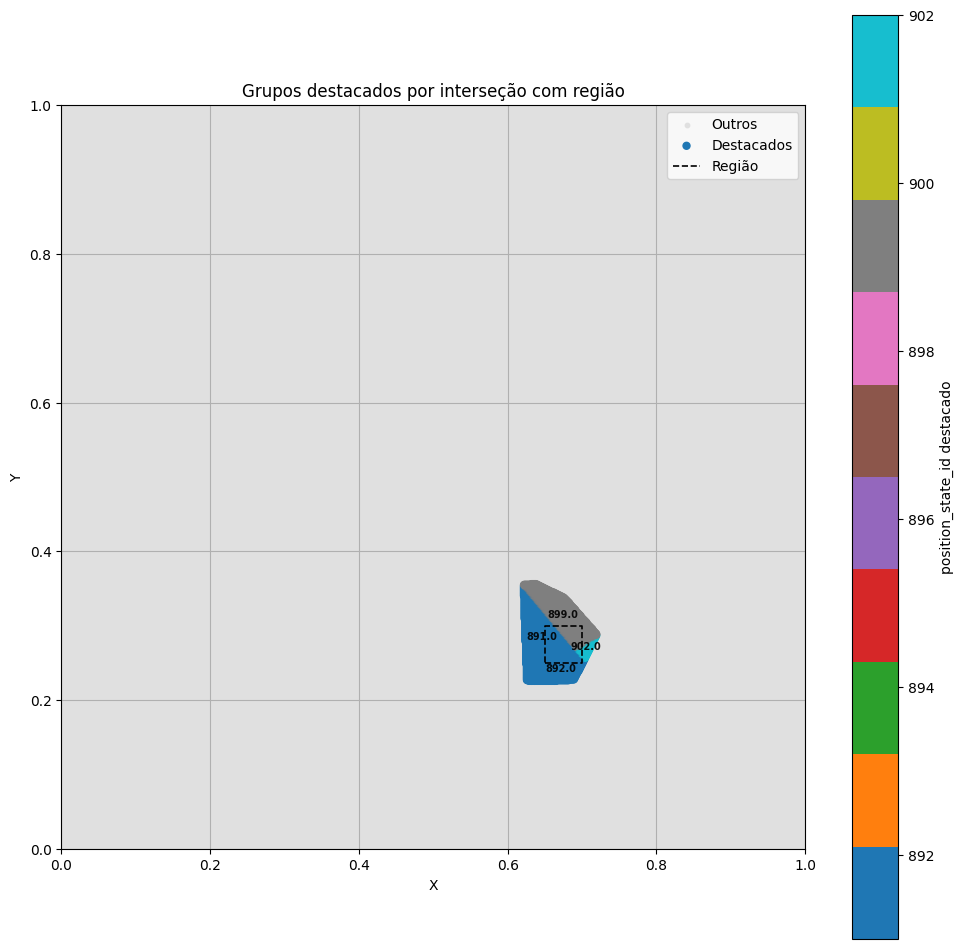

In [56]:
plot_position_states_w_region(apd, region=[0.65, 0.7, 0.25, 0.3])

/home/mgteus/workspace/navitrans/.nav/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


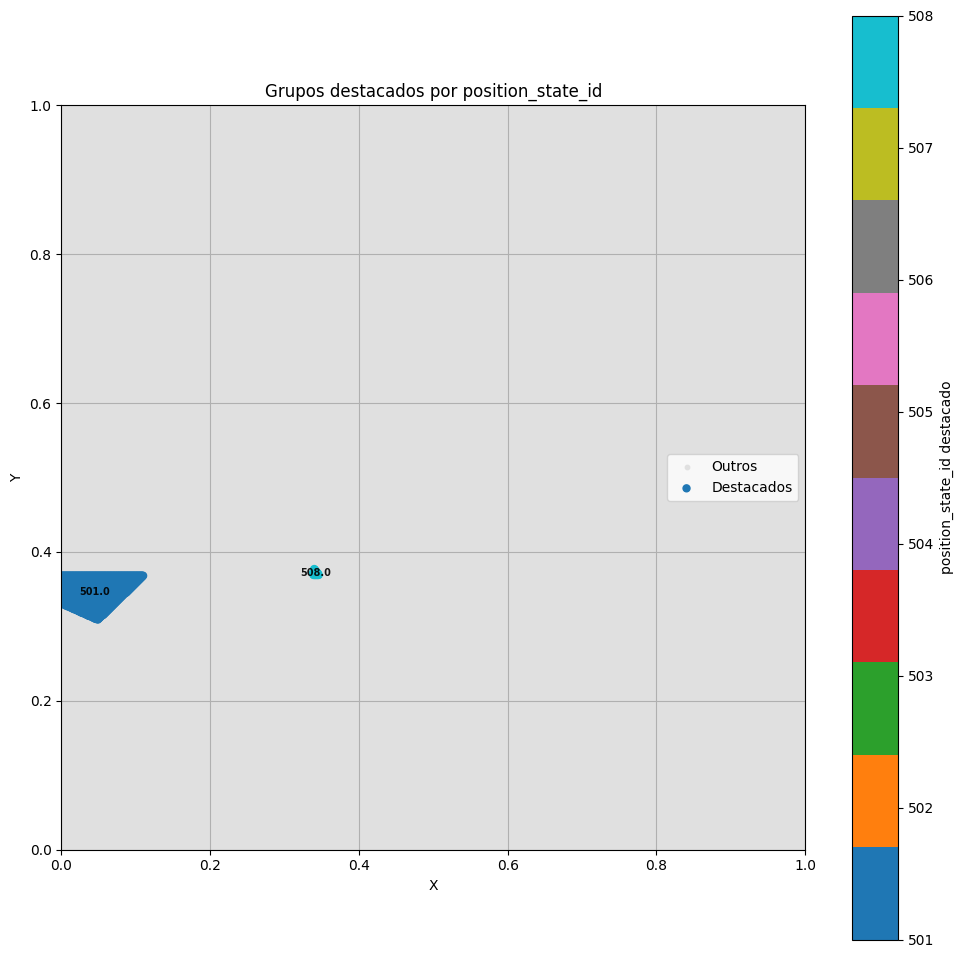

In [54]:
plot_position_states(apd, [501, 508])

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


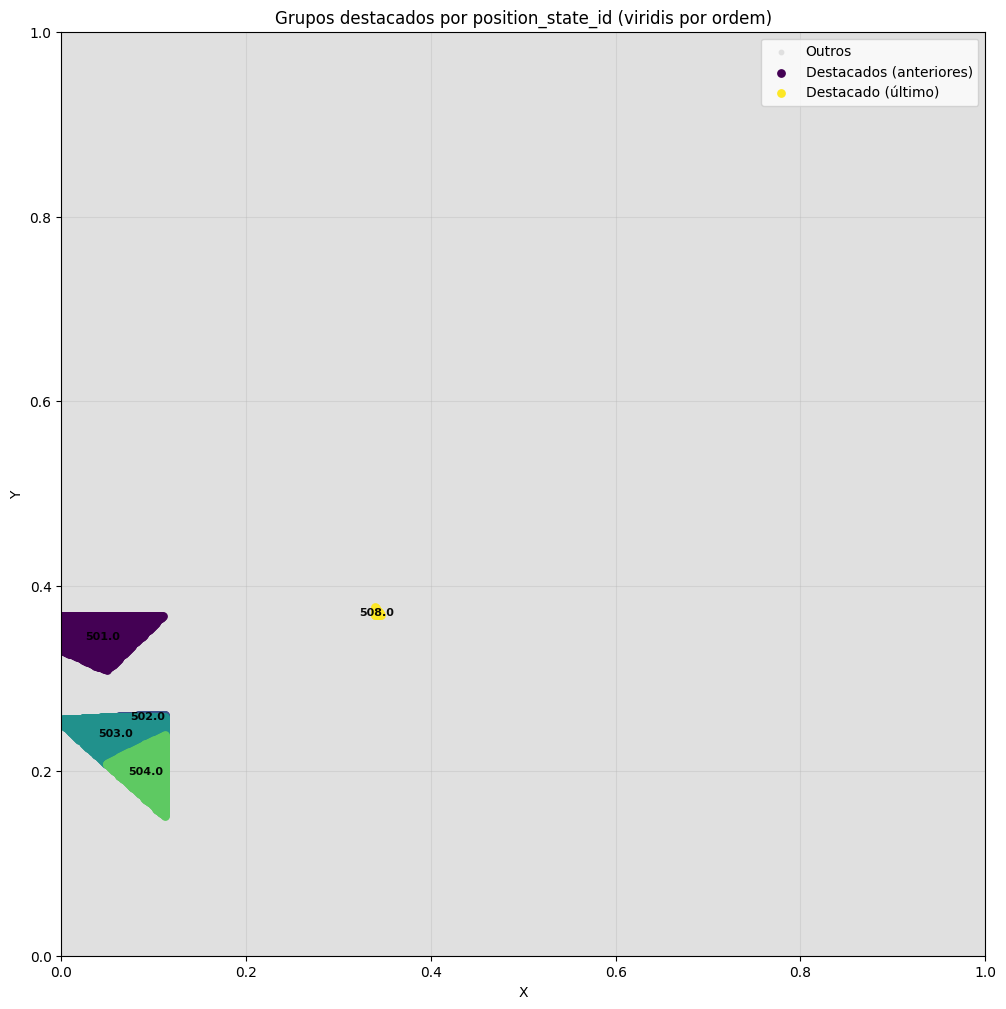

In [72]:
plot_position_states_w_title(apd, [501,502, 503, 504, 508])

In [63]:
def gerar_graficos_expansao(model, start_token, end_token, mask_token_id,
                             max_len,  apd, pasta_destino="imgs"):
    """
    Executa a expansão da trajetória e salva os gráficos das etapas destacando os grupos preditos.

    Parâmetros:
    - model: modelo de linguagem
    - start_token, end_token, mask_token_id, pad_token_id: tokens especiais
    - max_len: tamanho máximo da sequência
    - id_to_token: dicionário de id para string
    - apd: DataFrame com colunas 'X', 'Y', 'position_state_id'
    - pasta_destino: pasta onde os gráficos serão salvos
    """
    os.makedirs(pasta_destino, exist_ok=True)
    step = 0
    # Salva gráfico com os novos IDs destacados
    caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")
    device = next(model.parameters()).device
    sequence = [start_token, end_token]
    plot_position_states_w_title(apd, grupos_destacados=sequence, title=f"Passo {step:02} | {sequence[0]}->{sequence[1]}")
    plt.savefig(caminho_arquivo)
    plt.close()
    step +=1
    

    while len(sequence) < max_len:
        # Inserir [MASK] entre os pares
        new_sequence = []
        for i in range(len(sequence) - 1):
            new_sequence.append(sequence[i])
            new_sequence.append(mask_token_id)
        new_sequence.append(sequence[-1])
        sequence = new_sequence

        # Predição
        input_tensor = torch.tensor(sequence, dtype=torch.long).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(input_tensor)
            predictions = torch.argmax(logits, dim=-1).squeeze(0).cpu().tolist()

        # Substituição dos MASKs
        updated_sequence = []
        novos_ids = []
        for i, token in enumerate(sequence):
            if token == mask_token_id:
                predicted_token = predictions[i]
                updated_sequence.append(predicted_token)
                novos_ids.append(predicted_token)
            else:
                updated_sequence.append(token)

        sequence = updated_sequence
        print(sequence)
        
        # print(novos_ids)
        caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")
        plot_position_states_w_title(apd, grupos_destacados=updated_sequence, title=f"Passo {step:02}")
        plt.savefig(caminho_arquivo)
        plt.close()

        if len(sequence) >= max_len:
            break
        step += 1

    return


In [64]:
start_token = 501
end_token = 508
max_len = 20

In [73]:
gerar_graficos_expansao(
    model,
    start_token=start_token,
    end_token=end_token,
    mask_token_id=mask_token_id,
    max_len=max_len,
    apd=apd
)

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 507, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 583, 507, 501, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


...

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 583, 507, 501, 583, 507, 501, 583, 507, 583, 505, 507, 501, 507, 500, 340, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 507, 583, 501, 507, 505, 501, 507, 583, 507, 507, 340, 501, 507, 583, 501, 507, 507, 583, 501, 505, 501, 507, 501, 501, 501, 507, 501, 500, 505, 340, 507, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


In [60]:
def gerar_gif(pasta_imagens, nome_gif='legacy/media/trajetoria_animada.gif', duracao=1000):
    """
    Gera um GIF animado com os gráficos salvos.

    Parâmetros:
    - pasta_imagens: pasta onde estão os arquivos PNG
    - nome_gif: nome do arquivo de saída
    - duracao: duração entre os frames (em ms)
    """
    arquivos = sorted(glob.glob(os.path.join(pasta_imagens, "*.png")))
    imagens = [Image.open(arquivo) for arquivo in arquivos]

    if imagens:
        imagens[0].save(nome_gif, save_all=True, append_images=imagens[1:], duration=duracao, loop=0)
        print(f"GIF salvo como {nome_gif}")
    else:
        print("Nenhuma imagem encontrada para criar o GIF.")

In [61]:
# filepaths
fp_in = r"imgs/*.png"
fp_out = "legacy/media/gif_s25.gif"

# # # https://pillow.readthedocs.io/en/stable/handbook/image-file-formats.html#gif
img, *imgs = [Image.open(f) for f in sorted(glob.glob(fp_in))]
img.save(fp=fp_out, format='GIF', append_images=imgs,
         save_all=True, duration=500, loop=0)   

In [59]:
for i in sorted(glob.glob(fp_in)):
    print(i)

imgs/etapa_00.png
imgs/etapa_01.png
imgs/etapa_02.png
imgs/etapa_03.png
imgs/etapa_04.png


In [54]:
gerar_gif('imgs/', )

GIF salvo como trajetoria_animada.gif
